In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

In [14]:
df_sns = pd.read_csv('03_Clustering_Marketing.csv')
print('Dataset Shape:', df_sns.shape)
print(df_sns.head())

Dataset Shape: (15000, 40)
   gradyear gender     age  NumberOffriends  basketball  football  soccer  \
0      2007    NaN     NaN                0           0         0       0   
1      2007      F   17.41               49           0         0       1   
2      2007      F  17.511               41           0         0       0   
3      2006      F     NaN               36           0         0       0   
4      2008      F  16.657                1           0         0       0   

   softball  volleyball  swimming  ...  blonde  mall  shopping  clothes  \
0         0           0         0  ...       0     0         0        0   
1         0           0         1  ...       0     0         0        0   
2         0           0         0  ...       0     1         0        0   
3         0           0         0  ...       0     0         0        0   
4         0           0         1  ...       0     0         0        3   

   hollister  abercrombie  die  death  drunk  drugs  
0    

In [15]:
print(df_sns.info())
print(df_sns.describe())

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 40 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   gradyear         15000 non-null  int64
 1   gender           13663 non-null  str  
 2   age              12504 non-null  str  
 3   NumberOffriends  15000 non-null  int64
 4   basketball       15000 non-null  int64
 5   football         15000 non-null  int64
 6   soccer           15000 non-null  int64
 7   softball         15000 non-null  int64
 8   volleyball       15000 non-null  int64
 9   swimming         15000 non-null  int64
 10  cheerleading     15000 non-null  int64
 11  baseball         15000 non-null  int64
 12  tennis           15000 non-null  int64
 13  sports           15000 non-null  int64
 14  cute             15000 non-null  int64
 15  sex              15000 non-null  int64
 16  sexy             15000 non-null  int64
 17  hot              15000 non-null  int64
 18  kissed           

In [16]:
df_sns['age'] = pd.to_numeric(df_sns['age'], errors='coerce')
df_sns['age'].fillna(df_sns['age'].median(), inplace=True)
df_sns['gender'].fillna(df_sns['gender'].mode()[0], inplace=True)

/var/folders/70/s6bttn7d6_qdr8b28nj_vt640000gn/T/ipykernel_80321/2276469323.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df_sns['age'].fillna(df_sns['age'].median(), inplace=True)
/var/folders/70/s6bttn7d6_qdr8b28nj_vt640000gn/T/ipykernel_80321/2276469323.py:3: ChainedAssignmentError: A value is being set on a copy of a DataFr

0        F
1        F
2        F
3        F
4        F
        ..
14995    F
14996    F
14997    F
14998    F
14999    F
Name: gender, Length: 15000, dtype: str

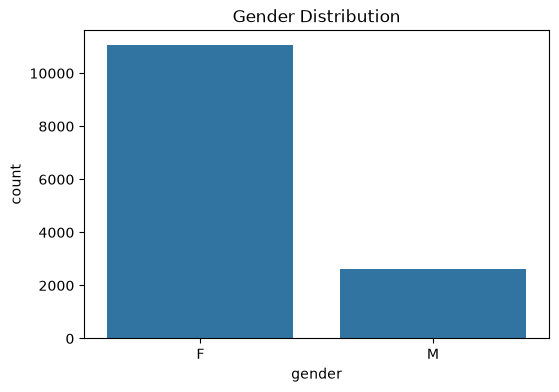

In [17]:
plt.figure(figsize=(6, 4))
sns.countplot(x='gender', data=df_sns)
plt.title('Gender Distribution')
plt.show()

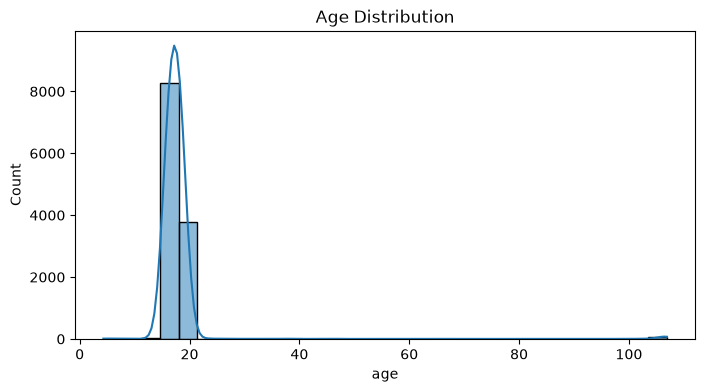

In [18]:
plt.figure(figsize=(8, 4))
sns.histplot(df_sns['age'], bins=30, kde=True)
plt.title('Age Distribution')
plt.show()

In [19]:
X = df_sns.drop(columns=['gradyear', 'gender'], errors='ignore')

In [20]:
X = X.apply(pd.to_numeric, errors='coerce')

In [21]:
for col in ['age', 'NumberOffriends']:
  if col in X.columns:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    X[col] = np.clip(X[col], lower, upper)

In [22]:
X.fillna(X.median(), inplace=True)

,age,NumberOffriends,basketball,football,soccer,softball,volleyball,swimming,cheerleading,baseball,...,blonde,mall,shopping,clothes,hollister,abercrombie,die,death,drunk,drugs
0,17.295,0.0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,17.410,49.0,0,0,1,0,0,1,0,0,...,0,0,0,0,0,0,0,0,1,0
2,17.511,41.0,0,0,0,0,0,0,0,1,...,0,1,0,0,0,0,0,0,1,1
3,17.295,36.0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,16.657,1.0,0,0,0,0,0,1,0,0,...,0,0,0,3,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,16.329,21.0,0,0,0,0,0,0,0,0,...,0,0,0,2,0,0,0,1,0,0
14996,16.545,50.0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
14997,17.999,32.0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
14998,17.903,20.0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [23]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [24]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)
kmeans_sil = silhouette_score(X_scaled, kmeans_labels)

In [25]:
hc = AgglomerativeClustering(n_clusters=4)
hc_labels = hc.fit_predict(X_scaled)
hc_sil = silhouette_score(X_scaled, hc_labels)

In [26]:
dbscan = DBSCAN(eps=3.5, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

if len(set(dbscan_labels)) > 1:
  dbscan_sil = silhouette_score(X_scaled, dbscan_labels)
else:
  dbscan_sil = -1

In [27]:
print(f'\n--- Model Silhouette Scores ---')
print(f'K-Means Silhouette Score: {kmeans_sil:.4f}')
print(f'Hierarchical Clustering Silhouette Score: {hc_sil:.4f}')
print(f'DBSCAN Silhouette Score: {dbscan_sil:.4f}')


--- Model Silhouette Scores ---
K-Means Silhouette Score: 0.2765
Hierarchical Clustering Silhouette Score: 0.1994
DBSCAN Silhouette Score: 0.0933


In [30]:
import joblib
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(kmeans, 'kmeans_model.pkl')

['kmeans_model.pkl']